In [1]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from google.colab import drive
from pathlib import Path
from numpy.random import randint

In [2]:
!pip install ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 23.7 MB/s eta 0:00:00


In [13]:
from ultralytics import YOLO

In [ ]:
import numpy as np

# 1. יצירת "תמונה" דמיונית בגודל 6x6 (נניח שערכי הפיקסלים הם עוצמת חום)
image = np.array([
    [10, 10, 10,  0,  0,  0],
    [10, 10, 10,  0,  0,  0],
    [10, 10, 10,  0,  0,  0],
    [10, 10, 10,  0,  0,  0],
    [10, 10, 10,  0,  0,  0],
    [10, 10, 10,  0,  0,  0]
])

# 2. הגדרת מסנן (Kernel) בגודל 3x3 לזיהוי קצוות אנכיים
# המסנן הזה ייתן ערך גבוה כשיש הבדל בין צד שמאל לצד ימין
kernel = np.array([
    [1, 0, -1],
    [1, 0, -1],
    [1, 0, -1]
])

def convolution2d(image, kernel, stride=1):
    img_h, img_w = image.shape
    f_h, f_w = kernel.shape

    # חישוב גודל הפלט (ללא Padding)
    out_h = (img_h - f_h) // stride + 1
    out_w = (img_w - f_w) // stride + 1
    output = np.zeros((out_h, out_w))

    # סריקת התמונה (Sliding Window)
    for y in range(0, out_h):
        for x in range(0, out_w):
            # חיתוך האזור הרלוונטי מהתמונה
            region = image[y*stride:y*stride+f_h, x*stride:x*stride+f_w]
            # פעולת המכפלה והסכימה (Element-wise multiplication & Sum)
            output[y, x] = np.sum(region * kernel)

    return output

# הרצת הפונקציה
feature_map = convolution2d(image, kernel, stride=1)

print("Feature Map (תוצאת הסריקה):")
print(feature_map)

Feature Map (תוצאת הסריקה):
[[ 0. 30. 30.  0.]
 [ 0. 30. 30.  0.]
 [ 0. 30. 30.  0.]
 [ 0. 30. 30.  0.]]


In [9]:
drive.mount('/content/drive')

image_path = r'/content/drive/My Drive/OREN/Python/Object Detection Project/Data/HIT-UAV-drone/data.yaml'

path_to_check = Path(image_path)

if path_to_check.exists():
    print("Success: The path exists!")
else:
    print("Error: The path does not exist. Check your spelling or Drive mount.")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Success: The path exists!


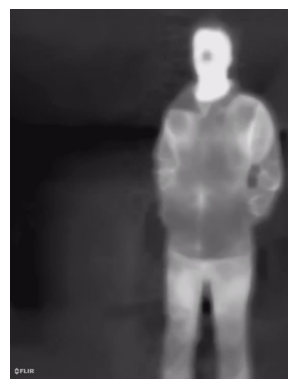

In [ ]:
img = mpimg.imread(image_path)

# Display the image
plt.imshow(img)
plt.axis('off') # Optional: hides the x and y axes
plt.show()

In [ ]:
def SplitTrainTest(X,Y):
  ind = np.random.RandomState(seed=42).permutation(len(Y))
  Ntrain = np.round(0.8 * len(Y))
  X_train = X[ind[:Ntrain]]
  Y_train = Y[ind[:Ntrain]]
  X_test = X[ind[Ntrain:]]
  Y_test = Y[ind[Ntrain:]]
  return X_train, Y_train, X_test, Y_test


NameError: name 'YOLO' is not defined

In [17]:
src = r'/content/drive/My Drive/OREN/Python/Object Detection Project/Data/HIT-UAV-drone/data.yaml'
des = r'/content/drive/My Drive/OREN/Python/Object Detection Project/codes/Training_HIV_dataset'

# Load the YOLOv8s model. If `yolov8s` is used as a string, Ultralytics downloads it if not found. '.pt' implies a local file.
model = YOLO('yolo8s')

# Train
results = model.train(
    data=src,
    optimizer='AdamW',
    epochs=250,
    imgsz=480,            # image size = 640
    device='cpu',         # Changed to 'cpu' as GPU device 0 was not accessible
    patience=50,            # Early stopping to prevent overfitting [cite: 75]
    augment=True,           # Enable standard augmentations [cite: 171]
    mosaic=1.0,             # High mosaic helps with small objects in UAV footage [cite: 168]
    mixup=0.2,              # Helps with overlapping objects [cite: 127]
    hsv_h=0.0,              # Set Hue to 0 (thermal images have no hue)
    hsv_s=0.0,              # Set Saturation to 0 (thermal images are grayscale)
    hsv_v=0.4,              # Keep Value (brightness) to handle exposure changes [cite: 124]
    verbose=True,          #
    plots=True,            # Ensure save plots
    val=True,              # Ensure validation is enabled (default is True)
    save_period=10,        # Save a checkpoint every 10 epochs
    batch=16,              # Adjust based on your GPU memory
    project=des,
    name='training_results_yolo8s2',
    save=True
)

FileNotFoundError: 'yolo8s' does not exist


image 1/1 /content/drive/My Drive/Object Detection Project/Data/FLIR DATA - Our data/images/val/image_200.jpg: 640x480 2 persons, 10.4ms
Speed: 2.5ms preprocess, 10.4ms inference, 0.4ms postprocess per image at shape (1, 3, 640, 480)
Results saved to /content/runs/detect/predict


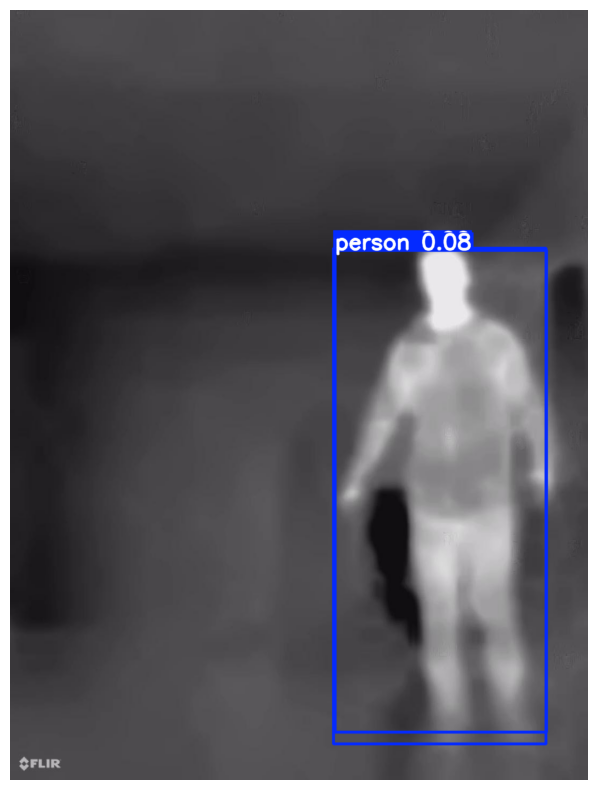

In [ ]:
# Predict on a single image from your Data folder
source_path = '/content/drive/My Drive/OREN/Python/Object Detection Project/Data/FLIR DATA - Our data/images/val/image_200.jpg'

results = model.predict(source=source_path, save=True, imgsz=640, conf=0.05)

for r in results:
    # 2. Generate the image with the boxes drawn on it
    # labels=True and boxes=True are default, but we ensure they are on
    im_array = r.plot(labels=True, boxes=True)

    # 3. CRITICAL: Convert BGR (OpenCV format) to RGB (Matplotlib format)
    # If you don't do this, people look blue and the sky looks orange!
    im_rgb = cv.cvtColor(im_array, cv.COLOR_BGR2RGB)

    # 4. Display
    plt.figure(figsize=(10, 10)) # Make it larger to see the boxes clearly
    plt.imshow(im_rgb)
    plt.axis('off')
    plt.show()

In [ ]:
!nvidia-smi


Thu Feb  5 16:51:18 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 550.54.15              Driver Version: 550.54.15      CUDA Version: 12.4     |
|-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   36C    P8              9W /   70W |       2MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
import os
import torch

# 1. Reset the environment variable to see the first GPU (index 0)
os.environ['CUDA_VISIBLE_DEVICES'] = '0'

# 2. Force PyTorch to check again
print(f"CUDA Available: {torch.cuda.is_available()}")
print(f"Device Name: {torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'None'}")

CUDA Available: True
Device Name: Tesla T4


In [ ]:
from ultralytics.data.converter import convert_coco

# drive.mount('/content/drive')

path = '/content/drive/My Drive/OREN/Python/Object Detection Project/Data/Test DATA'
dst_path = '/content/drive/My Drive/OREN/Python/Object Detection Project/Data/Test DATA YOLO format'


# Replace with the path to your COCO JSON annotations folder
# It will look for 'instances_train2017.json' etc. inside that folder
convert_coco(labels_dir=path,save_dir=dst_path, use_segments=False)

Annotations /content/drive/My Drive/OREN/Python/Object Detection Project/Data/Test DATA/Test_image_annotator.json: 100% ━━━━━━━━━━━━ 7/7 187.8it/s 0.0s
COCO data converted successfully.
Results saved to /content/drive/My Drive/OREN/Python/Object Detection Project/Data/Test DATA YOLO format2
